In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

IN_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Component01/intermediate/stage2_cleaned")        # Stage 2 output (cleaned, irregular rows)
STAGE2_REPORT = Path("/content/drive/MyDrive/Colab Notebooks/Component01/outputs/stage2_cleaning")          # gaps.csv, trip_metadata.csv
OUT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Component01/intermediate/stage3_synced")        # 1 Hz synchronised trips
REPORT_DIR = Path("/content/drive/MyDrive/Colab Notebooks/Component01/outputs/stage3_sync")
OUT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

trip_meta = pd.read_csv(STAGE2_REPORT / "trip_metadata.csv")

# start_s / end_s are SECONDS from the start of the raw log (not dates)
stage2_gaps = pd.read_csv(STAGE2_REPORT / "gaps.csv")
trip_meta["raw_start"] = pd.to_datetime(trip_meta["raw_start"])
print("gaps.csv:", len(stage2_gaps), "gaps |", stage2_gaps["type"].value_counts().to_dict())

trip_ids = sorted(p.stem for p in IN_DIR.glob("T*.csv"))
print(f"{len(trip_ids)} cleaned trips from Stage 2")

gaps.csv: 29 gaps | {'OBD dropout': 13, 'GPS gap while moving': 13, 'logging gap': 3}
77 cleaned trips from Stage 2


In [2]:
CFG = {
    "grid_s": 1,                    # target resolution: 1 Hz (standard for driving cycles, e.g. WLTP)
    "max_gap_speed_s": 8,           # interpolate OBD-type signals only across <= 8 s (~2 polling cycles of 3.7 s)
    "max_gap_gps_s": 5,             # GPS fixes are 1 s apart; bridge at most 4 missing fixes
    "max_hold_soc_s": 30,           # SoC changes in 0.1 % steps; hold last value at most 30 s
    "max_lag_s": 5,                 # search range for a clock offset between OBD and GPS
    "lag_min_corr": 0.8,            # only trust a lag estimate if the correlation is at least this strong
    "moving_kmh": 5,                # same definition of "moving" as Stage 1 and 2
    "obs_window_s": 0.5,            # a grid second is "observed" if a reading lies within +/- 0.5 s
}
pd.Series(CFG, name="value").to_frame()

,value
grid_s,1.0
max_gap_speed_s,8.0
max_gap_gps_s,5.0
max_hold_soc_s,30.0
max_lag_s,5.0
lag_min_corr,0.8
moving_kmh,5.0
obs_window_s,0.5


In [3]:
def load_clean(trip_id):
    df = pd.read_csv(IN_DIR / f"{trip_id}.csv", parse_dates=["timestamp"])
    base = df["timestamp"].iloc[0].floor("s")                  # whole second -> grid lands on clock seconds
    df["t_abs"] = (df["timestamp"] - base).dt.total_seconds()
    return df


def reading_intervals(df, col):
    """Time between consecutive readings of one signal (seconds)."""
    t = df.loc[df[col].notna(), "t_abs"]
    return t.diff().dropna()


signals = ["speed_kmh", "motor_rpm", "battery_current_a", "battery_voltage_v", "soc_pct", "gps_lat", "gps_speed_kmh"]
rows = []
for tid in trip_ids:
    df = load_clean(tid)
    for col in signals:
        iv = reading_intervals(df, col)
        rows.append({"signal": col, "median_s": iv.median(), "p95_s": iv.quantile(0.95), "readings": len(iv) + 1})
resolution = (pd.DataFrame(rows).groupby("signal")
              .agg(median_interval_s=("median_s", "median"), p95_interval_s=("p95_s", "median"),
                   readings_per_trip=("readings", "median"))
              .round(2).sort_values("median_interval_s"))
resolution

/tmp/ipykernel_960/3367510599.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv(IN_DIR / f"{trip_id}.csv", parse_dates=["timestamp"])


,median_interval_s,p95_interval_s,readings_per_trip
signal,,,
gps_lat,1.00,1.22,1720.0
battery_voltage_v,3.69,4.36,458.0
battery_current_a,3.70,4.35,458.0
motor_rpm,3.70,4.37,459.0
speed_kmh,3.70,4.39,459.0
soc_pct,3.70,4.38,459.0
gps_speed_kmh,5.94,24.01,221.0


In [4]:
def gps_speed_from_positions(df):
    """Speed (km/h) from distance between consecutive GPS fixes, placed at the midpoint time."""
    fx = df.loc[df["gps_lat"].notna(), ["t_abs", "gps_lat", "gps_lon"]]
    lat1, lon1 = np.radians(fx["gps_lat"].values[:-1]), np.radians(fx["gps_lon"].values[:-1])
    lat2, lon2 = np.radians(fx["gps_lat"].values[1:]), np.radians(fx["gps_lon"].values[1:])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    d = 2 * 6371000 * np.arcsin(np.sqrt(a))
    dt = np.diff(fx["t_abs"].values)
    ok = (dt > 0.5) & (dt <= 3)                                   # only consecutive fixes
    t_mid = (fx["t_abs"].values[:-1] + fx["t_abs"].values[1:]) / 2
    return pd.Series(d[ok] / dt[ok] * 3.6, index=t_mid[ok]).rolling(3, center=True, min_periods=1).median()


def interp_limited(t_obs, y_obs, t_grid, max_gap, method="pchip"):
    """Interpolate y onto t_grid, but only where the surrounding readings are at most max_gap apart.
    Returns values and a flag per grid point: 'observed', 'interpolated' or 'missing'."""
    out = np.full(len(t_grid), np.nan)
    flag = np.full(len(t_grid), "missing", dtype=object)
    if len(t_obs) == 0:
        return out, flag
    if len(t_obs) == 1:
        near = np.abs(t_grid - t_obs[0]) <= CFG["obs_window_s"]
        out[near], flag[near] = y_obs[0], "observed"
        return out, flag
    i = np.searchsorted(t_obs, t_grid)                       # index of the next reading
    prev_i, next_i = np.clip(i - 1, 0, len(t_obs) - 1), np.clip(i, 0, len(t_obs) - 1)
    inside = (t_grid >= t_obs[0]) & (t_grid <= t_obs[-1])
    gap = t_obs[next_i] - t_obs[prev_i]
    usable = inside & (gap <= max_gap)
    if method == "pchip":
        f = PchipInterpolator(t_obs, y_obs, extrapolate=False)
        out[usable] = f(t_grid[usable])
    elif method == "linear":
        out[usable] = np.interp(t_grid[usable], t_obs, y_obs)
    elif method == "hold":
        out[usable] = y_obs[prev_i[usable]]
    flag[usable] = "interpolated" if method != "hold" else "held"
    nearest = np.minimum(np.abs(t_grid - t_obs[prev_i]), np.abs(t_obs[next_i] - t_grid))
    obs = inside & (nearest <= CFG["obs_window_s"])
    flag[obs & usable] = "observed"
    return out, flag


def estimate_lag(t_grid, obd_speed, gps_speed_series):
    """Lag (s) that best aligns GPS-derived speed with OBD speed (positive = GPS is late)."""
    g = np.interp(t_grid, gps_speed_series.index.values, gps_speed_series.values, left=np.nan, right=np.nan)
    best = (0, -1.0)
    for lag in range(-CFG["max_lag_s"], CFG["max_lag_s"] + 1):
        shifted = np.roll(g, -lag)
        m = ~np.isnan(obd_speed) & ~np.isnan(shifted) & (obd_speed > CFG["moving_kmh"])
        m[:abs(lag)] = False; m[len(m) - abs(lag):] = False
        if m.sum() < 120:
            continue
        r = np.corrcoef(obd_speed[m], shifted[m])[0, 1]
        if r > best[1]:
            best = (lag, r)
    return best

In [5]:
def sync_trip(trip_id):
    df = load_clean(trip_id)
    t0 = df["timestamp"].iloc[0].floor("s")
    parts, diag = [], {"trip_id": trip_id}

    # --- clock offset between OBD and GPS (whole trip)
    grid_all = np.arange(np.ceil(df["t_abs"].iloc[0]), np.floor(df["t_abs"].iloc[-1]) + 1, CFG["grid_s"])
    s = df.loc[df["speed_kmh"].notna()]
    obd_all, _ = interp_limited(s["t_abs"].values, s["speed_kmh"].values, grid_all, CFG["max_gap_speed_s"])
    gps_spd = gps_speed_from_positions(df)
    lag, corr = estimate_lag(grid_all, obd_all, gps_spd) if len(gps_spd) > 120 else (0, np.nan)
    apply_lag = bool(lag != 0 and corr >= CFG["lag_min_corr"])
    diag.update({"lag_s": lag, "lag_corr": round(corr, 3), "lag_applied": apply_lag})
    if apply_lag:                                             # shift GPS timestamps onto the OBD clock
        gps_cols = ["gps_lat", "gps_lon", "gps_speed_kmh", "gps_altitude_m"]
        g = df[["t_abs"] + gps_cols].dropna(how="all", subset=gps_cols).copy()
        g["t_abs"] -= lag
        df = pd.concat([df.drop(columns=gps_cols), g], ignore_index=True).sort_values("t_abs")

    # --- OBD vs GPS speed scale (speedometer check), from Car Scanner's own GPS speed readings
    gs = df.loc[df["gps_speed_kmh"].notna(), ["t_abs", "gps_speed_kmh"]]
    obd_at_gps, _ = interp_limited(s["t_abs"].values, s["speed_kmh"].values, gs["t_abs"].values, CFG["max_gap_speed_s"])
    m = (gs["gps_speed_kmh"].values > 20) & (obd_at_gps > 20)
    diag["obd_over_gps_ratio"] = round(float(np.median(obd_at_gps[m] / gs["gps_speed_kmh"].values[m])), 4) if m.sum() > 30 else np.nan

    # --- build the 1 Hz grid per segment (never across a logging gap)
    for seg, d in df.groupby("segment_id"):
        grid = np.arange(np.ceil(d["t_abs"].min()), np.floor(d["t_abs"].max()) + 1, CFG["grid_s"])
        out = pd.DataFrame({"trip_id": trip_id, "segment_id": int(seg),
                            "timestamp": t0 + pd.to_timedelta(grid, unit="s"), "t_s": grid})

        def obs(col):
            x = d.loc[d[col].notna(), ["t_abs", col]].drop_duplicates("t_abs")
            return x["t_abs"].values, x[col].values

        out["speed_kmh"], out["speed_flag"] = interp_limited(*obs("speed_kmh"), grid, CFG["max_gap_speed_s"], "pchip")
        out["speed_kmh"] = out["speed_kmh"].clip(lower=0)
        out["motor_rpm"], out["rpm_flag"] = interp_limited(*obs("motor_rpm"), grid, CFG["max_gap_speed_s"], "linear")
        out["battery_current_a"], f_i = interp_limited(*obs("battery_current_a"), grid, CFG["max_gap_speed_s"], "linear")
        out["battery_voltage_v"], f_v = interp_limited(*obs("battery_voltage_v"), grid, CFG["max_gap_speed_s"], "linear")
        out["battery_power_kw"] = out["battery_voltage_v"] * out["battery_current_a"] / 1000
        rank = {"missing": 0, "interpolated": 1, "observed": 2}       # power is only as good as its weaker input
        out["battery_flag"] = [a if rank[a] <= rank[b] else b for a, b in zip(f_i, f_v)]
        out["soc_pct"], out["soc_flag"] = interp_limited(*obs("soc_pct"), grid, CFG["max_hold_soc_s"], "hold")
        out["gps_lat"], out["gps_flag"] = interp_limited(*obs("gps_lat"), grid, CFG["max_gap_gps_s"], "linear")
        out["gps_lon"], _ = interp_limited(*obs("gps_lon"), grid, CFG["max_gap_gps_s"], "linear")
        out["gps_altitude_m"], _ = interp_limited(*obs("gps_altitude_m"), grid, CFG["max_gap_gps_s"], "linear")
        gsp, gsf = interp_limited(*obs("gps_speed_kmh"), grid, 60, "linear")   # 60 s so readings are found; then keep observed only
        out["gps_speed_kmh"] = np.where(gsf == "observed", gsp, np.nan)
        parts.append(out)

    sync = pd.concat(parts, ignore_index=True)
    sync["t_s"] = sync["t_s"] - sync["t_s"].iloc[0]

    # --- diagnostics
    n = len(sync)
    diag["seconds"] = n
    for col in ("speed_flag", "gps_flag", "battery_flag"):
        vc = sync[col].value_counts(normalize=True)
        for k in ("observed", "interpolated", "missing"):
            diag[f"{col.split('_')[0]}_{k}_%"] = round(100 * vc.get(k, 0), 1)
    # distance check: 1 Hz speed vs trapezoid over the raw OBD readings (same segments)
    dist_sync = sync["speed_kmh"].fillna(0).sum() / 3600
    dist_raw = 0.0
    for _, d in df.groupby("segment_id"):
        r = d.loc[d["speed_kmh"].notna(), ["t_abs", "speed_kmh"]]
        dt = r["t_abs"].diff()
        ok = dt <= CFG["max_gap_speed_s"]
        dist_raw += float(((r["speed_kmh"] + r["speed_kmh"].shift()) / 2 * dt / 3600)[ok].sum())
    diag.update({"distance_raw_km": round(dist_raw, 3), "distance_1hz_km": round(dist_sync, 3)})
    acc = sync.groupby("segment_id")["speed_kmh"].diff() / 3.6
    diag.update({"max_accel_ms2": round(acc.max(), 2), "max_decel_ms2": round(acc.min(), 2)})
    return sync, diag

In [6]:
all_diag = []
for i, tid in enumerate(trip_ids, 1):
    sync, diag = sync_trip(tid)
    sync.to_csv(OUT_DIR / f"{tid}.csv", index=False)
    all_diag.append(diag)
    if i % 10 == 0 or i == len(trip_ids):
        print(f"{i}/{len(trip_ids)} trips synchronised")

diagnostics = pd.DataFrame(all_diag)
diagnostics.to_csv(REPORT_DIR / "sync_diagnostics.csv", index=False)
diagnostics.head(10)

/tmp/ipykernel_960/3367510599.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv(IN_DIR / f"{trip_id}.csv", parse_dates=["timestamp"])


10/77 trips synchronised
20/77 trips synchronised
30/77 trips synchronised
40/77 trips synchronised
50/77 trips synchronised
60/77 trips synchronised
70/77 trips synchronised
77/77 trips synchronised


,trip_id,lag_s,lag_corr,lag_applied,obd_over_gps_ratio,seconds,speed_observed_%,speed_interpolated_%,speed_missing_%,gps_observed_%,gps_interpolated_%,gps_missing_%,battery_observed_%,battery_interpolated_%,battery_missing_%,distance_raw_km,distance_1hz_km,max_accel_ms2,max_decel_ms2
0,T001,0,0.971,False,1.0151,1767,25.3,69.8,4.9,96.0,4.0,0.0,18.2,76.9,4.9,33.719,33.716,1.44,-4.09
1,T002,0,0.973,False,1.0152,1627,26.4,73.3,0.2,94.6,5.3,0.1,18.9,80.8,0.2,35.573,35.573,1.14,-2.30
2,T003,0,0.951,False,1.0151,1991,26.4,73.4,0.3,94.4,5.5,0.1,18.9,80.9,0.3,19.058,19.057,1.90,-2.27
3,T004,0,0.963,False,1.0148,2303,26.3,73.3,0.4,92.1,7.9,0.0,19.5,80.0,0.5,19.059,19.062,1.65,-2.41
4,T005,0,0.974,False,1.0151,1784,26.1,73.7,0.2,93.7,6.3,0.0,18.7,81.1,0.2,35.658,35.657,1.57,-2.55
5,T006,0,0.956,False,1.0180,3142,26.5,73.4,0.1,95.2,4.6,0.2,19.2,80.7,0.1,19.064,19.066,1.75,-2.10
6,T007,0,0.966,False,1.0147,1675,26.5,73.5,0.0,90.8,6.5,2.7,19.0,80.8,0.2,35.542,35.543,1.41,-2.06
7,T008,0,0.972,False,1.0159,1266,26.7,73.2,0.1,92.2,7.8,0.0,19.3,80.6,0.1,25.762,25.762,1.64,-2.64
8,T009,0,0.950,False,1.0094,5424,26.3,73.6,0.1,92.4,7.6,0.0,18.8,80.9,0.3,19.034,19.038,1.76,-2.41
9,T010,0,0.958,False,1.0132,3312,26.7,73.3,0.0,94.9,4.9,0.2,19.2,80.7,0.1,19.096,19.101,1.93,-2.04


In [7]:
lags = diagnostics["lag_s"].value_counts().sort_index()
print("Estimated OBD-GPS clock offset (s) -> number of trips:")
display(lags.to_frame("trips"))
print(f"Median correlation at the best lag: {diagnostics['lag_corr'].median():.3f}")
print(f"Trips where an offset was applied: {diagnostics['lag_applied'].sum()} of {len(diagnostics)}")
print(f"OBD speed / GPS speed (median over trips): {diagnostics['obd_over_gps_ratio'].median():.4f}")

Estimated OBD-GPS clock offset (s) -> number of trips:


,trips
lag_s,
0,77


Median correlation at the best lag: 0.967
Trips where an offset was applied: 0 of 77
OBD speed / GPS speed (median over trips): 1.0151


,observed,interpolated,missing
speed,26.2,72.8,1.0
gps,90.9,6.8,2.3
battery,19.2,79.8,1.0


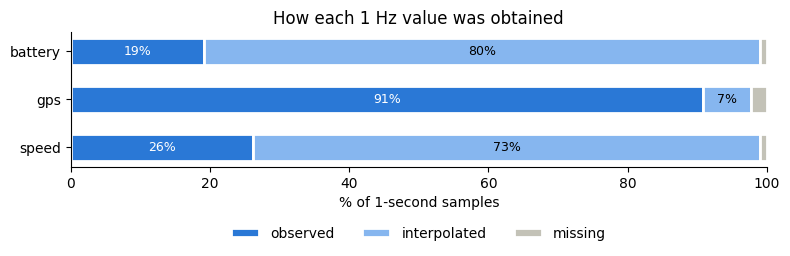

In [8]:
cov = pd.DataFrame({
    sig: {k: (diagnostics[f"{sig}_{k}_%"] * diagnostics["seconds"]).sum() / diagnostics["seconds"].sum()
          for k in ("observed", "interpolated", "missing")}
    for sig in ("speed", "gps", "battery")}).T.round(1)
display(cov)

fig, ax = plt.subplots(figsize=(8, 3))
left = np.zeros(len(cov))
colors = {"observed": "#2a78d6", "interpolated": "#86b6ef", "missing": "#c3c2b7"}
for k in ("observed", "interpolated", "missing"):
    ax.barh(cov.index, cov[k], left=left, color=colors[k], label=k, height=0.55, edgecolor="white", linewidth=2)
    for y, (l, v) in enumerate(zip(left, cov[k])):
        if v > 4:
            ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if k == "observed" else "black")
    left += cov[k].values
ax.set(xlim=(0, 100), xlabel="% of 1-second samples", title="How each 1 Hz value was obtained")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.35), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORT_DIR / "value_origin.png", dpi=150)
plt.show()

/tmp/ipykernel_960/3367510599.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv(IN_DIR / f"{trip_id}.csv", parse_dates=["timestamp"])
/tmp/ipykernel_960/368914225.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sync = pd.read_csv(OUT_DIR / f"{TRIP}.csv", parse_dates=["timestamp"])


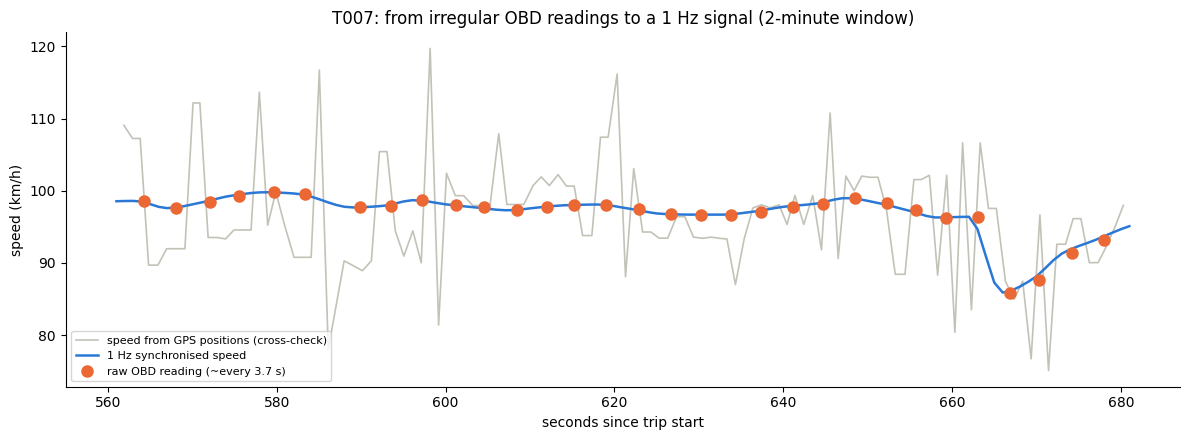

In [9]:
TRIP = diagnostics.sort_values("speed_missing_%").iloc[0]["trip_id"]       # a trip with full speed coverage
df = load_clean(TRIP)
sync = pd.read_csv(OUT_DIR / f"{TRIP}.csv", parse_dates=["timestamp"])
gps_spd = gps_speed_from_positions(df)

moving = sync.index[sync["speed_kmh"] > 20]
start = sync.loc[moving[len(moving) // 3], "t_s"]
win = (start, start + 120)                                                    # a 2-minute window
s_raw = df[df["speed_kmh"].notna() & df["t_abs"].between(*win)]
s_syn = sync[sync["t_s"].between(*win)]
g = gps_spd[(gps_spd.index >= win[0]) & (gps_spd.index <= win[1])]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(g.index, g.values, color="#c3c2b7", lw=1.2, label="speed from GPS positions (cross-check)")
ax.plot(s_syn["t_s"], s_syn["speed_kmh"], color="#2a78d6", lw=1.8, label="1 Hz synchronised speed")
ax.plot(s_raw["t_abs"], s_raw["speed_kmh"], "o", ms=8, color="#eb6834", label="raw OBD reading (~every 3.7 s)")
ax.set(xlabel="seconds since trip start", ylabel="speed (km/h)", title=f"{TRIP}: from irregular OBD readings to a 1 Hz signal (2-minute window)")
ax.legend(loc="lower left", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORT_DIR / "sync_example_speed.png", dpi=150)
plt.show()

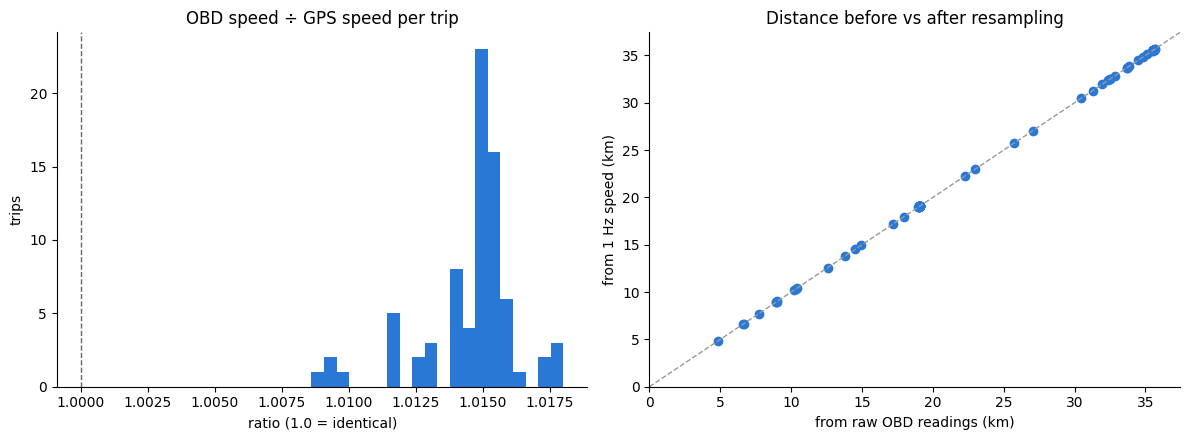

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
d = diagnostics.dropna(subset=["obd_over_gps_ratio"])
axes[0].hist(d["obd_over_gps_ratio"], bins=20, color="#2a78d6")
axes[0].axvline(1.0, color="0.4", ls="--", lw=1)
axes[0].set(title="OBD speed ÷ GPS speed per trip", xlabel="ratio (1.0 = identical)", ylabel="trips")
axes[1].plot(diagnostics["distance_raw_km"], diagnostics["distance_1hz_km"], "o", color="#2a78d6", ms=6)
lim = [0, diagnostics[["distance_raw_km", "distance_1hz_km"]].max().max() * 1.05]
axes[1].plot(lim, lim, color="0.6", lw=1, ls="--")
axes[1].set(title="Distance before vs after resampling", xlabel="from raw OBD readings (km)",
            ylabel="from 1 Hz speed (km)", xlim=lim, ylim=lim)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORT_DIR / "sync_checks.png", dpi=150)
plt.show()

In [11]:
  checks = {}
  raw_start = trip_meta.set_index("trip_id")["raw_start"]
  dropout_s_tested = 0
  for tid in trip_ids:
      s = pd.read_csv(OUT_DIR / f"{tid}.csv", parse_dates=["timestamp"])
      step = s.groupby("segment_id")["timestamp"].diff().dropna().dt.total_seconds()
      checks.setdefault("exactly 1 s between samples (within segments)", []).append(bool((step == 1).all()))
      checks.setdefault("speed within 0-200 km/h", []).append(bool(s["speed_kmh"].dropna().between(0, 200).all()))
      checks.setdefault("every value has a flag", []).append(
          bool(s["speed_flag"].notna().all() and s["gps_flag"].notna().all() and s["battery_flag"].notna().all()))
      checks.setdefault("missing flag <=> empty value", []).append(
          bool(((s["speed_flag"] == "missing") == s["speed_kmh"].isna()).all()))
      checks.setdefault("GPS speed readings kept (column not empty)", []).append(bool(s["gps_speed_kmh"].notna().any()))

      # nothing may be filled inside an OBD dropout recorded by Stage 2.

      # nothing may be filled inside an OBD dropout recorded by Stage 2.
      # Gap times are seconds from the RAW log start -> convert to clock time, then compare with Stage 3 timestamps.
      dz = stage2_gaps[(stage2_gaps["trip_id"] == tid) & (stage2_gaps["type"] == "OBD dropout")]
      inside = pd.Series(False, index=s.index)
      for _, gp in dz.iterrows():
          a = raw_start[tid] + pd.to_timedelta(gp["start_s"] + 4, unit="s")    # 4 s margin = one polling cycle
          b = raw_start[tid] + pd.to_timedelta(gp["end_s"] - 4, unit="s")
          inside |= s["timestamp"].between(a, b)
      dropout_s_tested += int(inside.sum())
      checks.setdefault("no speed filled inside OBD dropouts", []).append(bool((s.loc[inside, "speed_flag"] == "missing").all()))

  d = diagnostics
  checks["distance preserved (within 1 %)"] = list(
      (abs(d["distance_1hz_km"] - d["distance_raw_km"]) <= 0.01 * d["distance_raw_km"]).values)
  checks["acceleration physically plausible (|a| <= 5 m/s2)"] = list(
      ((d["max_accel_ms2"] <= 5) & (d["max_decel_ms2"] >= -5)).values)

  print(f"Seconds inside OBD dropouts that were actually tested: {dropout_s_tested:,} "
        f"(must be > 0, otherwise the dropout check tests nothing)")
  verification = pd.DataFrame({k: [f"{sum(v)}/{len(v)}", "PASS" if all(v) else "CHECK"] for k, v in checks.items()},
                              index=["trips passing", "result"]).T
  verification

/tmp/ipykernel_960/3764707190.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  s = pd.read_csv(OUT_DIR / f"{tid}.csv", parse_dates=["timestamp"])


Seconds inside OBD dropouts that were actually tested: 1,141 (must be > 0, otherwise the dropout check tests nothing)


,trips passing,result
exactly 1 s between samples (within segments),77/77,PASS
speed within 0-200 km/h,77/77,PASS
every value has a flag,77/77,PASS
missing flag <=> empty value,77/77,PASS
GPS speed readings kept (column not empty),77/77,PASS
no speed filled inside OBD dropouts,77/77,PASS
distance preserved (within 1 %),77/77,PASS
acceleration physically plausible (|a| <= 5 m/s2),77/77,PASS


In [12]:
print("STAGE 3 – GPS–OBD SYNCHRONISATION: KEY RESULTS")
print("-" * 60)
print(f"Trips synchronised: {len(diagnostics)}  |  1 Hz samples: {diagnostics['seconds'].sum():,} "
      f"({diagnostics['seconds'].sum() / 3600:.1f} h)")
print(f"Raw resolution: OBD speed every ~{resolution.loc['speed_kmh', 'median_interval_s']} s, "
      f"GPS fixes every ~{resolution.loc['gps_lat', 'median_interval_s']} s")
print(f"Clock offset: most common lag {diagnostics['lag_s'].mode().iloc[0]} s, "
      f"applied in {diagnostics['lag_applied'].sum()} trips")
print(f"Speedometer check: OBD reads {100 * (diagnostics['obd_over_gps_ratio'].median() - 1):+.1f} % vs GPS")
for sig in cov.index:
    print(f"{sig:8s}: {cov.loc[sig, 'observed']}% observed, {cov.loc[sig, 'interpolated']}% interpolated, "
          f"{cov.loc[sig, 'missing']}% missing")
print("Verification:", "all checks PASS" if (verification["result"] == "PASS").all() else "see table above")

STAGE 3 – GPS–OBD SYNCHRONISATION: KEY RESULTS
------------------------------------------------------------
Trips synchronised: 77  |  1 Hz samples: 163,461 (45.4 h)
Raw resolution: OBD speed every ~3.7 s, GPS fixes every ~1.0 s
Clock offset: most common lag 0 s, applied in 0 trips
Speedometer check: OBD reads +1.5 % vs GPS
speed   : 26.2% observed, 72.8% interpolated, 1.0% missing
gps     : 90.9% observed, 6.8% interpolated, 2.3% missing
battery : 19.2% observed, 79.8% interpolated, 1.0% missing
Verification: all checks PASS


In [13]:
# ---------------------------------------------------------------
# Stage 3 method validation
#   A. lag detection: shift GPS by a KNOWN offset and check it is recovered
#   B. interpolation accuracy: 1 Hz OBD speed vs independent GPS speed,
#      on observed seconds vs interpolated seconds
# ---------------------------------------------------------------
# ---- A. lag recovery test (on a copy; nothing is saved)
tid = diagnostics.sort_values("speed_missing_%").iloc[0]["trip_id"]
df = load_clean(tid)
s = df.loc[df["speed_kmh"].notna()]
grid = np.arange(np.ceil(df["t_abs"].iloc[0]), np.floor(df["t_abs"].iloc[-1]) + 1)
obd, _ = interp_limited(s["t_abs"].values, s["speed_kmh"].values, grid, CFG["max_gap_speed_s"])
gps = gps_speed_from_positions(df)
rows = []
for true_lag in (-4, -2, 0, 1, 2, 3, 5, 7):
    shifted = pd.Series(gps.values, index=gps.index + true_lag)          # GPS clock true_lag s late
    lag, r = estimate_lag(grid, obd, shifted)
    rows.append({"injected_lag_s": true_lag, "estimated_lag_s": lag, "corr": round(r, 3),
                 "recovered": lag == true_lag})
lag_test = pd.DataFrame(rows)
lag_test.to_csv(REPORT_DIR / "validation_lag_recovery.csv", index=False)
print(f"A. Lag recovery on {tid} (search range +/-{CFG['max_lag_s']} s; 7 s is outside it on purpose)")
display(lag_test)

# ---- B. interpolation accuracy against Car Scanner's own GPS speed (independent sensor)
ratio = diagnostics["obd_over_gps_ratio"].median()          # remove the known +1.5 % speedometer offset
parts = []
for t in trip_ids:
    x = pd.read_csv(OUT_DIR / f"{t}.csv", usecols=["speed_kmh", "speed_flag", "gps_speed_kmh"])
    x = x[x["gps_speed_kmh"].notna() & x["speed_kmh"].notna() & (x["gps_speed_kmh"] > 5)]
    parts.append(x.assign(err=x["speed_kmh"] / ratio - x["gps_speed_kmh"]))
e = pd.concat(parts)
acc = e.groupby("speed_flag")["err"].agg(
    seconds="size", bias_kmh="mean",
    MAE_kmh=lambda v: v.abs().mean(), RMSE_kmh=lambda v: np.sqrt((v ** 2).mean()),
    p95_abs_kmh=lambda v: v.abs().quantile(0.95)).round(2)
acc.to_csv(REPORT_DIR / "validation_interpolation_accuracy.csv")
print("B. 1 Hz OBD speed vs GPS speed (after removing the 1.5 % offset).")
print("   'observed' = baseline sensor disagreement; 'interpolated' should be only slightly worse.")
display(acc)

A. Lag recovery on T007 (search range +/-5 s; 7 s is outside it on purpose)


/tmp/ipykernel_960/3367510599.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv(IN_DIR / f"{trip_id}.csv", parse_dates=["timestamp"])


,injected_lag_s,estimated_lag_s,corr,recovered
0,-4,-4,0.966,True
1,-2,-2,0.966,True
2,0,0,0.966,True
3,1,1,0.966,True
4,2,2,0.966,True
5,3,3,0.966,True
6,5,5,0.966,True
7,7,5,0.962,False


B. 1 Hz OBD speed vs GPS speed (after removing the 1.5 % offset).
   'observed' = baseline sensor disagreement; 'interpolated' should be only slightly worse.


,seconds,bias_kmh,MAE_kmh,RMSE_kmh,p95_abs_kmh
speed_flag,,,,,
interpolated,12363,-0.02,0.55,0.88,1.83
observed,4237,0.00,0.38,0.59,1.17
